In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data = {
    "Product": ["Laptop", "Mouse", "Keyboard", "Monitor", "Laptop",
                "Mouse", "Keyboard", "Monitor", "Laptop", "Mouse"],
    "Category": ["Electronics", "Accessories", "Accessories", "Electronics",
                 "Electronics", "Accessories", "Accessories", "Electronics",
                 "Electronics", "Accessories"],
    "Quantity": [2, 5, 3, 1, 4, 8, 2, 3, 1, 6],
    "Unit_Price": [50000, 500, 1200, 12000, 50000,
                   500, 1200, 12000, 50000, 500],
    "Region": ["North", "South", "East", "West", "North",
               "South", "East", "West", "North", "South"],
    "Profit": [8000, 300, 600, 2000, 15000,
               500, 350, 3500, 4000, 450]
}

df = pd.DataFrame(data)

df["Total_Sales"] = df["Quantity"] * df["Unit_Price"]

df

,Product,Category,Quantity,Unit_Price,Region,Profit,Total_Sales
0,Laptop,Electronics,2,50000,North,8000,100000
1,Mouse,Accessories,5,500,South,300,2500
2,Keyboard,Accessories,3,1200,East,600,3600
3,Monitor,Electronics,1,12000,West,2000,12000
4,Laptop,Electronics,4,50000,North,15000,200000
5,Mouse,Accessories,8,500,South,500,4000
6,Keyboard,Accessories,2,1200,East,350,2400
7,Monitor,Electronics,3,12000,West,3500,36000
8,Laptop,Electronics,1,50000,North,4000,50000
9,Mouse,Accessories,6,500,South,450,3000


**Task 1**

In [7]:
mean_sales = df["Total_Sales"].mean()
median_sales = df["Total_Sales"].median()
mode_sales = df["Total_Sales"].mode()

print("Mean Sales:", mean_sales)
print("Median Sales:", median_sales)
print("Mode Sales:", mode_sales.tolist())

Mean Sales: 41350.0
Median Sales: 8000.0
Mode Sales: [2400, 2500, 3000, 3600, 4000, 12000, 36000, 50000, 100000, 200000]


**Task 2**

In [8]:
variance = df["Total_Sales"].var()
std_deviation = df["Total_Sales"].std()

print("Variance:", variance)
print("Standard Deviation:", std_deviation)

Variance: 4099082777.7777777
Standard Deviation: 64024.0796714625


**Task 3**

In [9]:
#Correlation
correlation = df["Quantity"].corr(df["Total_Sales"])

print("Correlation:", correlation)
if correlation > 0:
    print("Positive Relationship")
elif correlation < 0:
    print("Negative Relationship")
else:
    print("No Linear Relationship")


# Probability
total_products = len(df)
laptop_count = (df["Product"] == "Laptop").sum()

probability = laptop_count / total_products

print("Total Records:", total_products)
print("Laptop Records:", laptop_count)
print("Probability:", probability)
print("Probability Percentage:", probability * 100, "%")


Correlation: -0.15205098407956225
Negative Relationship


**Task 4**

In [11]:
# Task 4: Outlier Detection

Q1 = df["Total_Sales"].quantile(0.25)
Q3 = df["Total_Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df["Total_Sales"] < lower_limit) |
              (df["Total_Sales"] > upper_limit)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Outliers:")
print(outliers[["Product", "Total_Sales"]])

Q1: 3150.0
Q3: 46500.0
IQR: 43350.0
Lower Limit: -61875.0
Upper Limit: 111525.0
Outliers:
  Product  Total_Sales
4  Laptop       200000


**Task 5**

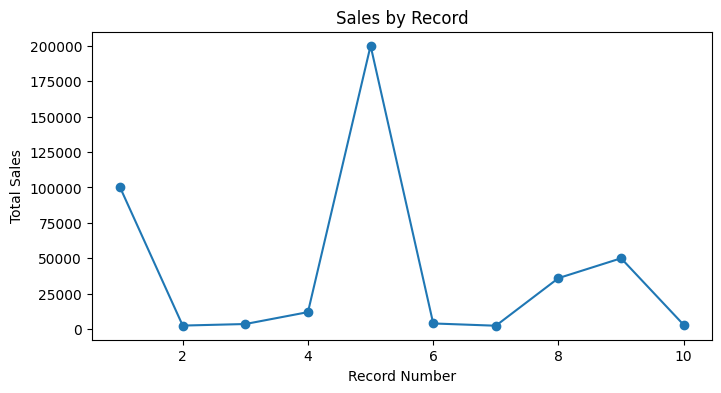

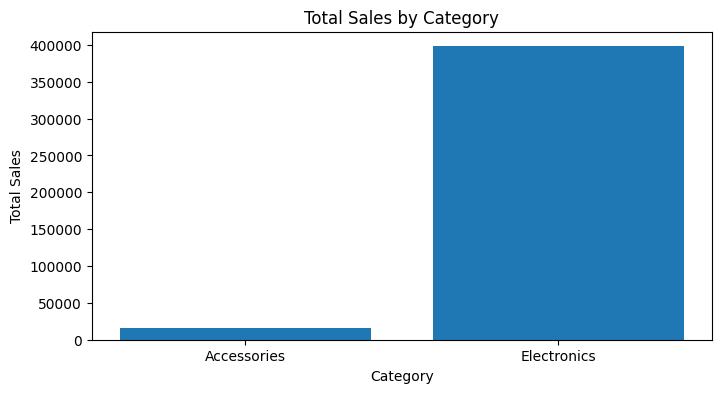

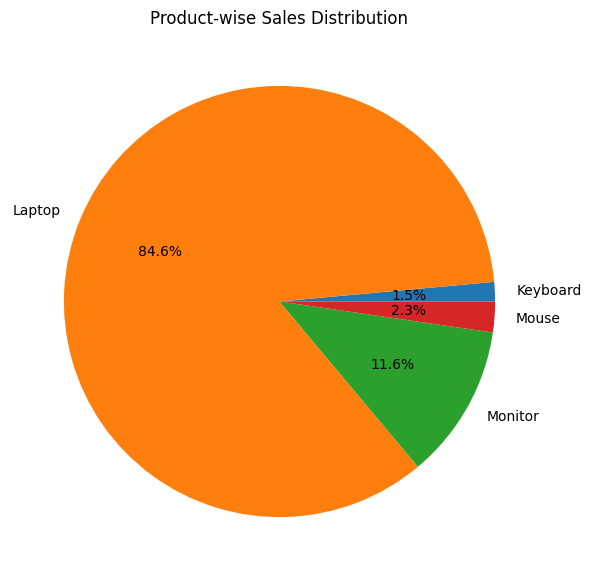

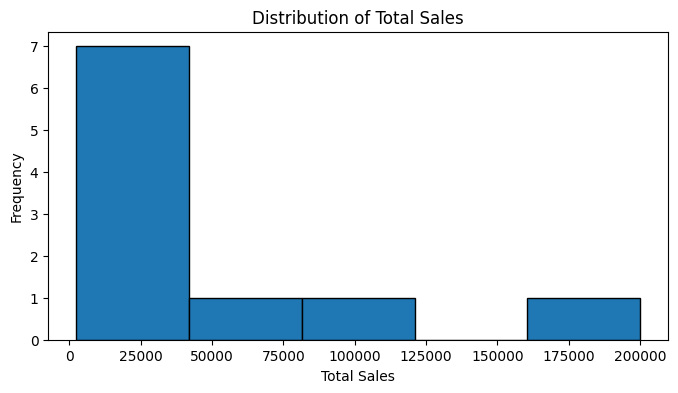

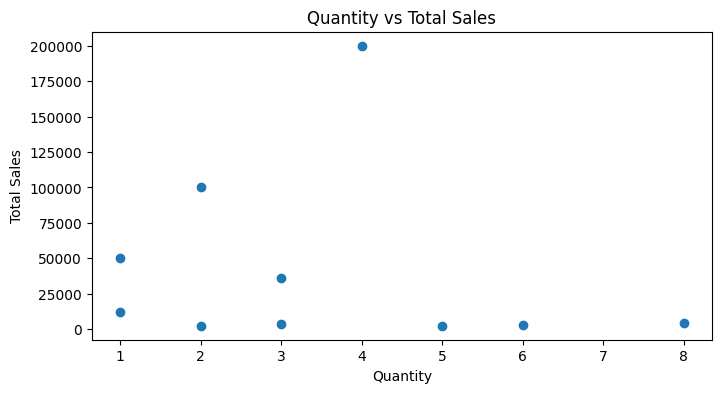

In [14]:
# Line Chart
plt.figure(figsize=(8, 4))
plt.plot(df.index + 1, df["Total_Sales"], marker="o")
plt.title("Sales by Record")
plt.xlabel("Record Number")
plt.ylabel("Total Sales")
plt.show()

# Bar Chart
category_sales = df.groupby("Category")["Total_Sales"].sum()
plt.figure(figsize=(8, 4))
plt.bar(category_sales.index, category_sales.values)
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()


# Pie Chart
product_sales = df.groupby("Product")["Total_Sales"].sum()
plt.figure(figsize=(7, 7))
plt.pie(product_sales.values,
        labels=product_sales.index,
        autopct="%1.1f%%")
plt.title("Product-wise Sales Distribution")
plt.show()


# Histogram
plt.figure(figsize=(8, 4))
plt.hist(df["Total_Sales"], bins=5, edgecolor="black")
plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")
plt.show()


# Scatter Plot
plt.figure(figsize=(8, 4))
plt.scatter(df["Quantity"], df["Total_Sales"])
plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")
plt.show()

**Task 6**

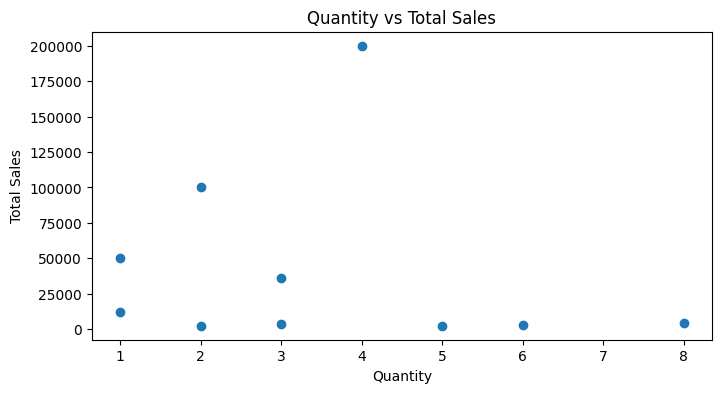

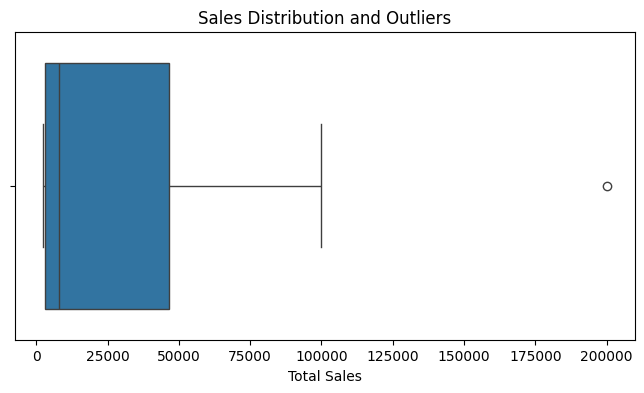

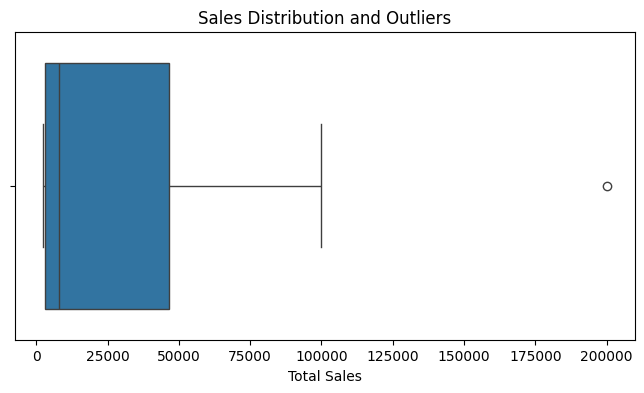

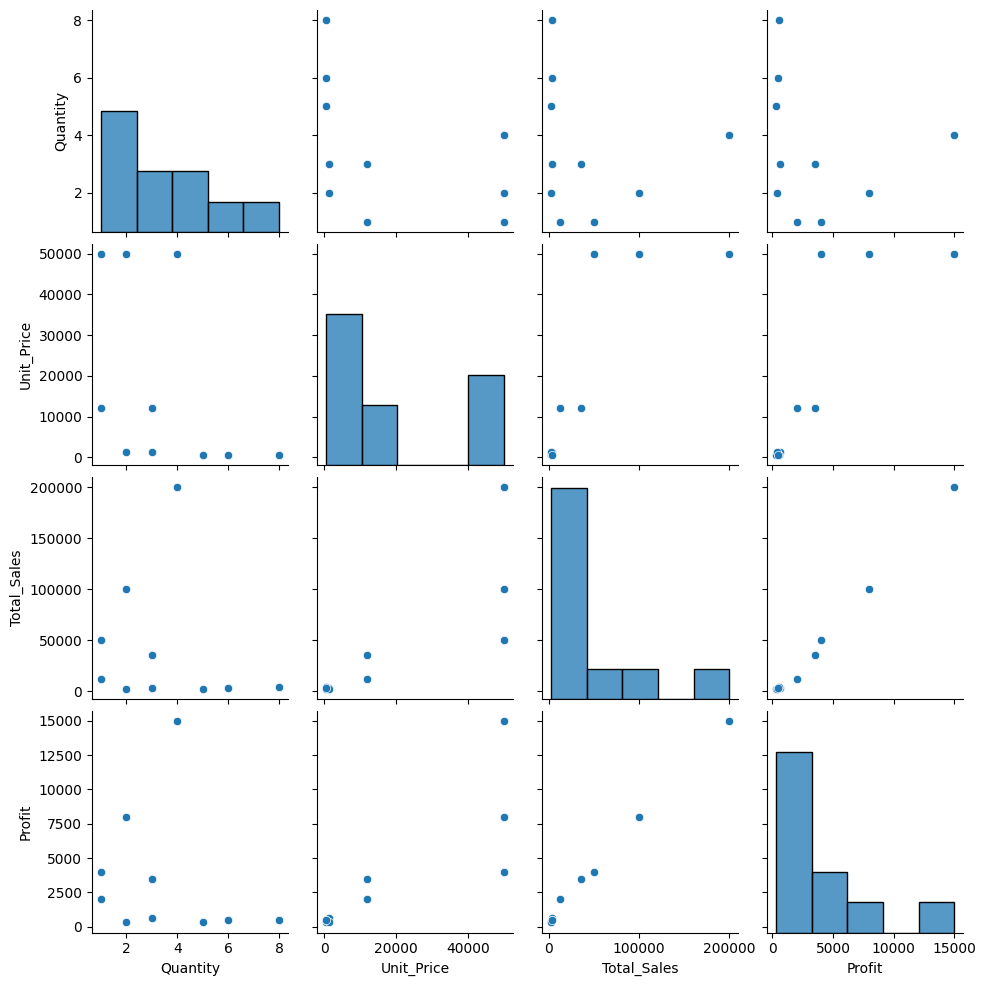

In [16]:
# Scatter Plot

plt.figure(figsize=(8, 4))
plt.scatter(df["Quantity"], df["Total_Sales"])
plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")
plt.show()


# Box Plot

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Total_Sales")
plt.title("Sales Distribution and Outliers")
plt.xlabel("Total Sales")
plt.show()


# Box Plot

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Total_Sales")
plt.title("Sales Distribution and Outliers")
plt.xlabel("Total Sales")
plt.show()


# Pair Plot

sns.pairplot(df[["Quantity", "Unit_Price", "Total_Sales", "Profit"]])
plt.show()

**Task 7**

In [18]:
# Data Inspection

print("First 5 Rows:")
print(df.head())
print("\nDataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nData Types:")
print(df.dtypes)
print("\nStatistical Summary:")
print(df.describe())


# Create a copy for cleaning

df_clean = df.copy()
df_clean.loc[0, "Profit"] = np.nan
df_clean.loc[1, "Region"] = np.nan
df_clean.loc[2, "Quantity"] = -3
df_clean = pd.concat([df_clean, df_clean.iloc[[0]]], ignore_index=True)
print("Dataset Before Cleaning:")
print(df_clean)

#Check missing values
print("Missing Values:")
print(df_clean.isnull().sum())



#Check Duplicate Records
print("Duplicate Records:", df_clean.duplicated().sum())

#Check invalid values
print("Invalid Quantity Records:")
print(df_clean[df_clean["Quantity"] <= 0])

#Data clean
# Handle missing values

df_clean["Profit"] = df_clean["Profit"].fillna(df_clean["Profit"].median())

df_clean["Region"] = df_clean["Region"].fillna(df_clean["Region"].mode()[0])

# Remove duplicates

df_clean = df_clean.drop_duplicates()

# Remove invalid quantity records

df_clean = df_clean[df_clean["Quantity"] > 0]

# Reset index

df_clean = df_clean.reset_index(drop=True)
print("Dataset After Cleaning:")
print(df_clean)
print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())
print("\nDuplicate Records After Cleaning:")
print(df_clean.duplicated().sum())

First 5 Rows:
    Product     Category  Quantity  Unit_Price Region  Profit  Total_Sales
0    Laptop  Electronics         2       50000  North    8000       100000
1     Mouse  Accessories         5         500  South     300         2500
2  Keyboard  Accessories         3        1200   East     600         3600
3   Monitor  Electronics         1       12000   West    2000        12000
4    Laptop  Electronics         4       50000  North   15000       200000

Dataset Shape:
(10, 7)

Column Names:
Index(['Product', 'Category', 'Quantity', 'Unit_Price', 'Region', 'Profit',
       'Total_Sales'],
      dtype='object')

Data Types:
Product        object
Category       object
Quantity        int64
Unit_Price      int64
Region         object
Profit          int64
Total_Sales     int64
dtype: object

Statistical Summary:
       Quantity    Unit_Price        Profit    Total_Sales
count  10.00000     10.000000     10.000000      10.000000
mean    3.50000  17790.000000   3470.000000   41350.000

**Task 8**

Correlation Matrix:
             Quantity  Unit_Price  Total_Sales    Profit
Quantity     1.000000   -0.488618    -0.172306 -0.091598
Unit_Price  -0.488618    1.000000     0.812508  0.594385
Total_Sales -0.172306    0.812508     1.000000  0.874505
Profit      -0.091598    0.594385     0.874505  1.000000


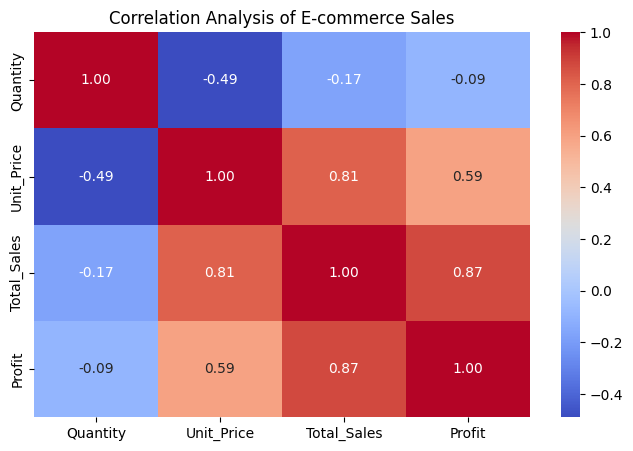

Category-wise Total Sales:
Category
Electronics    398000
Accessories     11900
Name: Total_Sales, dtype: int64


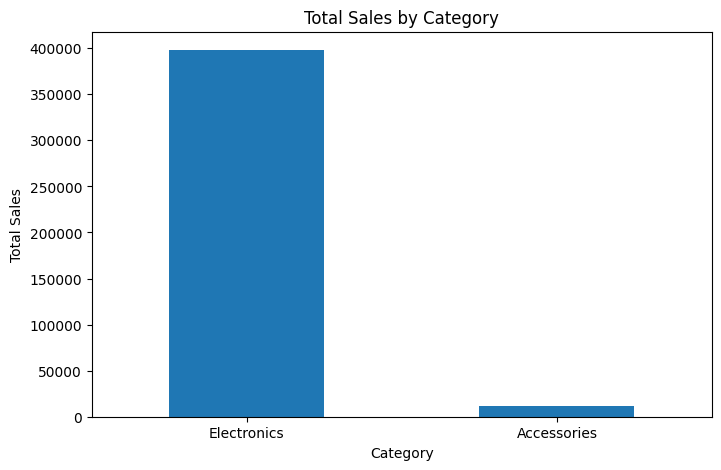

Region-wise Total Profit:
Region
North    19900.0
West      5500.0
South      950.0
East       350.0
Name: Profit, dtype: float64


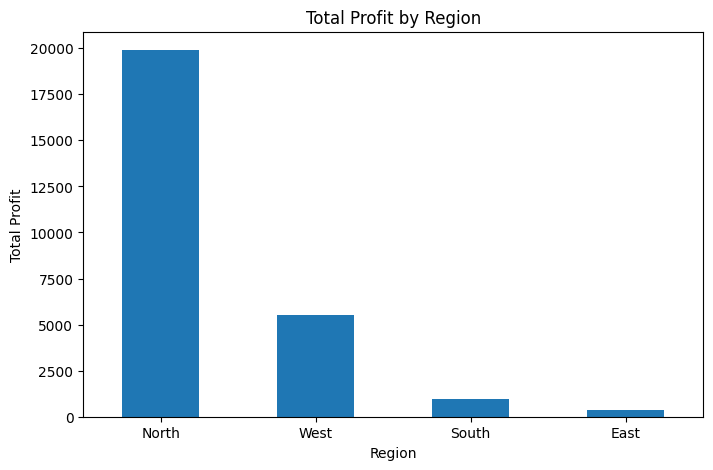

Correlation between Quantity and Total Sales: -0.17230576738092196


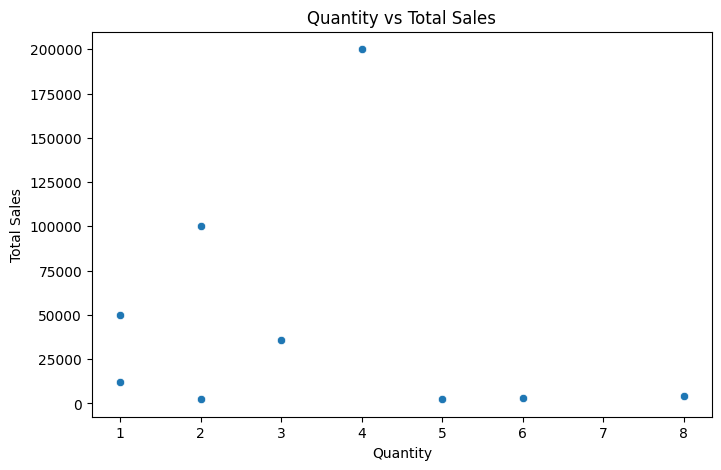

INSIGHTS
1. Category-wise sales analysis identifies the categories contributing the most to total sales.
2. Region-wise profit analysis helps compare profitability across different regions.
3. Correlation analysis helps identify the direction and strength of linear relationships between numerical variables.
4. The scatter plot visualizes the relationship between quantity sold and total sales.
5. The correlation heatmap provides an overview of relationships among numerical variables.


In [19]:
# 1. Correlation Analysis

numeric_columns = ["Quantity", "Unit_Price", "Total_Sales", "Profit"]

correlation_matrix = df_clean[numeric_columns].corr()

print("Correlation Matrix:")
print(correlation_matrix)


# 2. Correlation Heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Analysis of E-commerce Sales")
plt.show()


# 3. Category-wise Sales Analysis

category_sales = df_clean.groupby("Category")["Total_Sales"].sum().sort_values(ascending=False)

print("Category-wise Total Sales:")
print(category_sales)

plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()


# 4. Region-wise Profit Analysis

region_profit = df_clean.groupby("Region")["Profit"].sum().sort_values(ascending=False)

print("Region-wise Total Profit:")
print(region_profit)

plt.figure(figsize=(8, 5))

region_profit.plot(kind="bar")

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)

plt.show()


# 5. Quantity vs Total Sales

correlation = df_clean["Quantity"].corr(df_clean["Total_Sales"])

print("Correlation between Quantity and Total Sales:", correlation)

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_clean, x="Quantity", y="Total_Sales")

plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")

plt.show()


# 6. Important Insights

print("INSIGHTS")

print("1. Category-wise sales analysis identifies the categories contributing the most to total sales.")

print("2. Region-wise profit analysis helps compare profitability across different regions.")

print("3. Correlation analysis helps identify the direction and strength of linear relationships between numerical variables.")

print("4. The scatter plot visualizes the relationship between quantity sold and total sales.")

print("5. The correlation heatmap provides an overview of relationships among numerical variables.")

**Task 9**


**Recommendation 1**: Improve Product Category Planning

**Observation**: Category-wise sales analysis helps identify which product categories generate the highest and lowest sales.

**Recommendation**: The business should focus on understanding customer demand for each category. It can maintain sufficient stock for high-demand categories and review pricing, product selection, and promotional strategies for categories with lower sales.

**Business Benefit**: This can help improve inventory planning, reduce unnecessary stock, and increase sales opportunities.



**Recommendation 2**: Improve Regional Profitability

**Observation**: Region-wise profit analysis helps compare the profit generated by different regions.

**Recommendation**: The business should investigate regions with lower total profits to understand whether pricing, operating costs, discounts, or product demand are affecting profitability. Based on the findings, it can adjust its pricing and marketing strategies.

**Business Benefit**: This can help improve profit margins and support better regional business decisions.